In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv", encoding='latin-1')
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [37]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [38]:
df.shape

(541909, 8)

In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [40]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [41]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [42]:
(df.isnull().sum()/len(df))*100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [43]:
df["Description"] = df["Description"].fillna("Unknown")

In [44]:
df = df.dropna(subset=["CustomerID"])

In [45]:
df.isnull().sum()


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [46]:
df.duplicated().sum()

np.int64(5225)

In [47]:
df = df.drop_duplicates()

In [48]:
df.duplicated().sum()


np.int64(0)

In [49]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [50]:
df.info()

<class 'pandas.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  str           
 1   StockCode    401604 non-null  str           
 2   Description  401604 non-null  str           
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[us]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  float64       
 7   Country      401604 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 27.6 MB


In [51]:

df[df["Quantity"] <= 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [52]:
df = df[df["Quantity"] > 0]

In [53]:
df[df["UnitPrice"] <= 0]    

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


In [54]:
df = df[df["UnitPrice"] > 0]

In [55]:
cancelled = df["InvoiceNo"].str.startswith("C", na=False).sum()

print("Cancelled Invoices:", cancelled)

if cancelled > 0:
    df = df[~df["InvoiceNo"].str.startswith("C", na=False)]
    print("Cancelled invoices removed.")
else:
    print("No cancelled invoices found.")

Cancelled Invoices: 0
No cancelled invoices found.


In [56]:
df["InvoiceNo"].dtype

<StringDtype(storage='python', na_value=nan)>

In [57]:
df["InvoiceNo"].str.startswith("C", na=False).sum()

np.int64(0)

In [58]:
print(df["InvoiceNo"].head(10).tolist())

['536365', '536365', '536365', '536365', '536365', '536365', '536365', '536366', '536366', '536367']


In [59]:
df[df["InvoiceNo"].str.contains("C", na=False)]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [60]:
df.info()

<class 'pandas.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  str           
 1   StockCode    392692 non-null  str           
 2   Description  392692 non-null  str           
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  float64       
 7   Country      392692 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 27.0 MB


In [61]:
# Count of InvoiceNo starting with 'C' (cancelled orders)
original_df = pd.read_csv("data.csv", encoding='latin-1')
cancelled_count = original_df["InvoiceNo"].astype(str).str.startswith("C").sum()
print(f"Number of invoices starting with 'C': {cancelled_count}")

Number of invoices starting with 'C': 9288


In [62]:
# Save cleaned dataframe as new CSV
df.to_csv("cleaned_data.csv", index=False)
print("Saved as cleaned_data.csv")

Saved as cleaned_data.csv


In [63]:
df["Description"].unique()

<StringArray>
[ 'WHITE HANGING HEART T-LIGHT HOLDER',                 'WHITE METAL LANTERN',
      'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE',
      'RED WOOLLY HOTTIE WHITE HEART.',        'SET 7 BABUSHKA NESTING BOXES',
   'GLASS STAR FROSTED T-LIGHT HOLDER',              'HAND WARMER UNION JACK',
           'HAND WARMER RED POLKA DOT',       'ASSORTED COLOUR BIRD ORNAMENT',
 ...
     'SILVER AND BLACK ORBIT NECKLACE',           'LETTER "F" BLING KEY RING',
           'LETTER "O" BLING KEY RING',           'LETTER "T" BLING KEY RING',
           'LETTER "U" BLING KEY RING',           'LETTER "W" BLING KEY RING',
           'LETTER "Z" BLING KEY RING',      'PINK CRYSTAL SKULL PHONE CHARM',
  'CREAM HANGING HEART T-LIGHT HOLDER',         'PAPER CRAFT , LITTLE BIRDIE']
Length: 3877, dtype: str

In [64]:
for col in df.columns:
    print(col, df[col].nunique())

InvoiceNo 18532
StockCode 3665
Description 3877
Quantity 301
InvoiceDate 17282
UnitPrice 440
CustomerID 4338
Country 37


In [65]:
df["StockCode"].unique()

<StringArray>
['85123A',  '71053', '84406B', '84029G', '84029E',  '22752',  '21730',
  '22633',  '22632',  '84879',
 ...
  '23562',  '23561', '90214F', '90214O', '90214T', '90214U', '90214W',
 '90214Z',  '90089',  '23843']
Length: 3665, dtype: str

In [66]:
df["InvoiceNo"].unique()


<StringArray>
['536365', '536366', '536367', '536368', '536369', '536370', '536371',
 '536372', '536373', '536374',
 ...
 '581578', '581579', '581580', '581581', '581582', '581583', '581584',
 '581585', '581586', '581587']
Length: 18532, dtype: str

In [67]:
df["Quantity"].max()

np.int64(80995)

In [68]:
df.groupby("StockCode")["Description"].nunique().sort_values(ascending=False).head(10)

StockCode
23196     4
23236     4
22937     3
17107D    3
23203     3
22776     3
23126     3
23131     3
23209     3
23231     3
Name: Description, dtype: int64

In [70]:
df["TotalSales"] = (
    df["Quantity"] * df["UnitPrice"]
)

In [71]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [72]:
print(df["TotalSales"].sum())
print(df["InvoiceNo"].nunique())
print(df["CustomerID"].nunique())
print(df["Quantity"].sum())

8887208.894000001
18532
4338
5152002


In [73]:
df["Month"] = df["InvoiceDate"].dt.to_period("M")

monthly_sales = df.groupby("Month")["TotalSales"].sum()

In [74]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,2011-12
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,2011-12
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011-12
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011-12


In [76]:
top_products = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


In [77]:
top_revenue_products = (
    df.groupby("Description")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_revenue_products)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: TotalSales, dtype: float64


In [78]:
country_sales = (
    df.groupby("Country")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_sales)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: TotalSales, dtype: float64


In [79]:
outside_uk = df[df["Country"] != "United Kingdom"]

outside_uk.groupby("Country")["TotalSales"].sum() \
    .sort_values(ascending=False).head(10)

Country
Netherlands    285446.34
EIRE           265262.46
Germany        228678.40
France         208934.31
Australia      138453.81
Spain           61558.56
Switzerland     56443.95
Belgium         41196.34
Sweden          38367.83
Japan           37416.37
Name: TotalSales, dtype: float64

In [81]:
top_customers = (
    df.groupby("CustomerID")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: TotalSales, dtype: float64


In [82]:
df["Day"] = df["InvoiceDate"].dt.day_name()

In [83]:
day_sales = df.groupby("Day")["TotalSales"].sum()
print(day_sales)

Day
Friday       1483080.811
Monday       1363604.401
Sunday        785490.321
Thursday     1973015.730
Tuesday      1697733.801
Wednesday    1584283.830
Name: TotalSales, dtype: float64


In [85]:
df["Hour"] = df["InvoiceDate"].dt.hour

hour_sales = df.groupby("Hour")["TotalSales"].sum()

print(hour_sales)

Hour
6           4.250
7       31059.210
8      281997.790
9      842392.341
10    1259267.591
11    1101177.600
12    1373695.390
13    1168724.200
14     991992.821
15     963559.680
16     467380.560
17     233811.591
18     104744.990
19      48568.400
20      18832.480
Name: TotalSales, dtype: float64


In [86]:
df["InvoiceNo"].nunique()

18532

In [89]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalSales', 'Month', 'Day',
       'Hour'],
      dtype='str')

In [90]:
order_value = (
    df.groupby("InvoiceNo")["TotalSales"]
    .sum()
)

order_value.head()

InvoiceNo
536365    139.12
536366     22.20
536367    278.73
536368     70.05
536369     17.85
Name: TotalSales, dtype: float64

In [91]:
average_order_value = order_value.mean()

print("Average Order Value:", average_order_value)

Average Order Value: 479.56016047917126


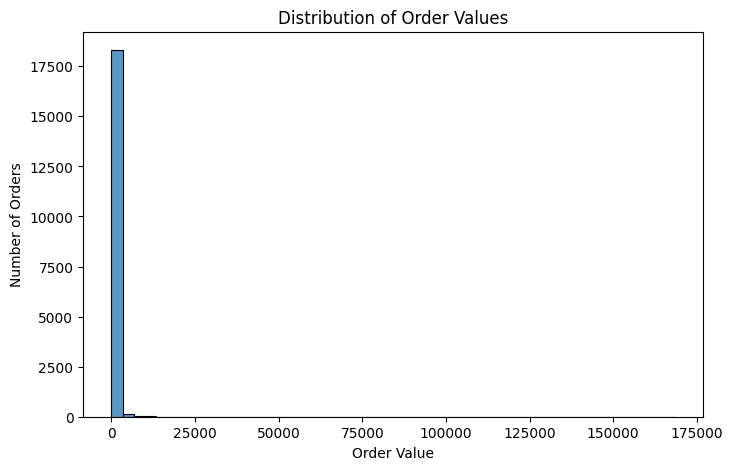

In [92]:
plt.figure(figsize=(8, 5))

sns.histplot(order_value, bins=50)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.show()

In [93]:
items_per_order = (
    df.groupby("InvoiceNo")["Quantity"]
    .sum()
)

items_per_order.mean()

np.float64(278.00571983595944)

In [94]:
customer_orders = (
    df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

customer_orders.head()

CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
Name: InvoiceNo, dtype: int64

In [95]:
one_time = (customer_orders == 1).sum()

repeat = (customer_orders > 1).sum()

print("One-time customers:", one_time)
print("Repeat customers:", repeat)

One-time customers: 1493
Repeat customers: 2845


In [96]:
repeat_percentage = (
    repeat / len(customer_orders)
) * 100

print("Repeat Customer %:", repeat_percentage)

Repeat Customer %: 65.58321807284463


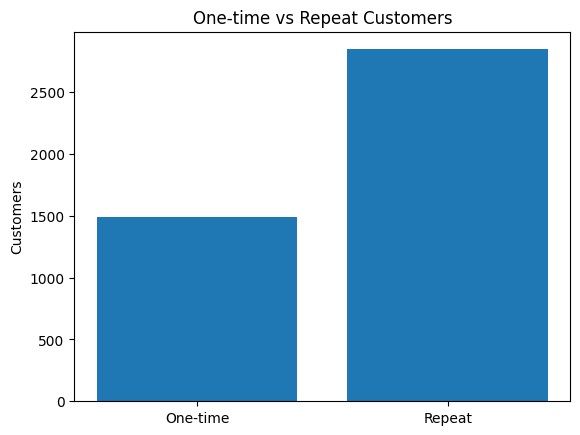

In [97]:
labels = ["One-time", "Repeat"]
values = [one_time, repeat]

plt.bar(labels, values)

plt.title("One-time vs Repeat Customers")
plt.ylabel("Customers")

plt.show()

In [98]:
customer_revenue = (
    df.groupby("CustomerID")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

In [101]:
total_revenue = customer_revenue.sum().round(2)
print(total_revenue)

8887208.89


In [102]:
top10_revenue = customer_revenue.head(10).sum()

top10_percentage = (
    top10_revenue / total_revenue
) * 100

print("Top 10 Customer Revenue %:", top10_percentage)

Top 10 Customer Revenue %: 17.301936176274573


In [103]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"]
)

reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

In [104]:
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalSales": "sum"
})

In [105]:
rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
